# 14-eval — Đánh giá S1: bảng kết quả đo gì, và cuối pipeline điểm đi đâu

**Câu hỏi**: trên GC10, bảng S1 của bước 14 (All, Old, New, S0test, M_f, M_d) đo gì; lớp cũ mất điểm theo cơ chế nào; ảnh lớp mới sai rơi vào đâu; và qua 15 ảnh chụp, mỗi bước 09–14 lấy của lớp cũ và lớp mới bao nhiêu điểm? (D15, D25, Q08.02, Q14.04; T và B cho E09.07 phần 2; QD24, QD25)

### Nguồn gốc

Mẫu cell 0 (`lab/README.vi.md` §11): in commit và trạng thái dirty, rồi đặt `XLA_FLAGS` ở chế độ GPU tất định trước mọi lần import jax.

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "lab")]
import replay; os.environ["XLA_FLAGS"] = replay._xla_flags()   # GPU deterministic mode before any jax import
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes",
                               ":(exclude)lab/*.ipynb", ":(exclude)lab/*.md")),
      "| XLA_FLAGS", os.environ["XLA_FLAGS"])

commit 9898be0 | code dirty False | XLA_FLAGS --xla_gpu_deterministic_ops=true


- **Kết quả**: commit `9898be0`, code dirty False, XLA_FLAGS `--xla_gpu_deterministic_ops=true`.

## 1. Kiểm

### 1.1 Chạy lại bước 14 ở r0 s4; hằng đẳng thức của bảng S1 trên 15 ảnh chụp

Chạy lại bước 14 của `gc10_v2_ft_r0_s4` từ ảnh chụp 13 bằng `replay.rerun`, rồi so khoá `acc1` (4 độ chính xác của bảng S1) với ảnh chụp 14.

Trên 15 `metrics.json`, đổi mỗi dòng của bảng ra số ảnh đúng, rồi kiểm năm hằng đẳng thức mà `scripts/extract_vbcgcd.py` ngầm dùng ở t1:
- `test_old_x` trùng `test0_x`: ở phiên 1, test lớp cũ là test của phiên 0 (`test_dataloader`, mode `old`);
- S1_All = (số đúng của Old + số đúng của New)/455;
- S1_S0test = S1_Old;
- M_d = S1_New, vì chỉ có một phiên;
- M_f = S0_S0test − S1_Old, in kèm số ảnh; final_All = S1_All.

Đã thấy trước: bảng của r0 s4, gồm All 70.11, Old 81.74, New 57.01, S0test 81.74 (`metrics.json`; `nb-v1` cell 9); các số trong 15 `metrics.json`.

Dự đoán [SUY LUẬN]:
- `rerun` OK 1/1 khoá, lệch 0. Bước 14 không rút ngẫu nhiên và chỉ chấm, nên 4 số thực tính từ số nguyên phải trùng;
- bảng r0 s4: 319/455, 197/241, 122/214, 197/241;
- năm hằng đẳng thức đúng ở 15/15;
- số ảnh của M_f (tôi đã tính từ `metrics.json`): 11, 11, 7, 9, 9 / 6, 7, 6, 4, 4 / 13, 15, 13, 11, 11. Ở §3.1, các số này phải trùng số ảnh test cũ bị khe mới cướp.

In [2]:
# 1.1 rerun step 14 (S1 table with params1) and compare acc1 with snap/14.pkl; identities of the S1 table over the 15
#     default chains, as scripts/extract_vbcgcd.py uses them at t1: S0 row = Old row, S1_All, M_d, M_f, final_All
import io, contextlib, json, time
import numpy as np
import pandas as pd

RUN = "gc10_v2_ft_r0_s4"
RUNS = [f"gc10_v2_ft_r{r}_s{s}" for r in range(3) for s in range(5)]
buf, t0 = io.StringIO(), time.time()
with contextlib.redirect_stdout(buf):
    out, ok = replay.rerun(RUN, "14")
log = buf.getvalue()
print("\n".join(l for l in log.splitlines() if l.startswith(("rerun", "  OK", "  DIFF", "+", "|"))))
print(f"time {time.time() - t0:.0f} s | acc1 of the rerun: {out['acc1']}")

cnt = lambda a, n: a * n / 100                                       # accuracy (%) -> number of right images
rows11 = []
for run in RUNS:
    o4 = replay.snapshots(run)["04"]["out"]
    m = json.loads((replay._run_dir(run) / "metrics.json").read_text())
    n_old, n_new = len(o4["true_test_old_y"]), len(o4["true_test1_y"])
    c = {k: cnt(m[k], n) for k, n in (("S0_S0test", n_old), ("S1_Old", n_old), ("S1_New", n_new), ("S1_All", n_old + n_new))}
    rows11.append(dict(snap=run.replace("gc10_v2_ft_", ""), n_old=n_old, n_new=n_new,
                       S0=round(c["S0_S0test"], 4), Old=round(c["S1_Old"], 4), New=round(c["S1_New"], 4), All=round(c["S1_All"], 4),
                       same_test=bool(np.array_equal(o4["test_old_x"], o4["test0_x"])),
                       all_eq=abs(c["S1_All"] - c["S1_Old"] - c["S1_New"]) < 1e-6,
                       s0row_eq=m["S1_S0test"] == m["S1_Old"],
                       Md_eq=m["M_d"] == round(m["S1_New"], 2),
                       Mf_eq=m["M_f"] == round(m["S0_S0test"] - m["S1_Old"], 2),
                       final_eq=m["final_All"] == m["S1_All"],
                       Mf=m["M_f"], Mf_imgs=round(c["S0_S0test"] - c["S1_Old"], 4)))
T11 = pd.DataFrame(rows11).set_index("snap")
print(T11.to_string())
chk = ["same_test", "all_eq", "s0row_eq", "Md_eq", "Mf_eq", "final_eq"]
print("identities hold:", {k: f"{int(T11[k].sum())}/15" for k in chk})
print("M_f in images per FT seed:", {r: T11.loc[[i for i in T11.index if i.startswith(r)], "Mf_imgs"].tolist() for r in ("r0", "r1", "r2")})

/home/rito/miniforge3/envs/vbcgcd/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


rerun step 14 of gc10_v2_ft_r0_s4 | device gpu | GPU now NVIDIA GeForce RTX 4060 Laptop GPU, 621.14 | GPU of the run NVIDIA GeForce RTX 4060 Laptop GPU, 617.42 | driver differs: float outputs may move in the last bits
+---------+---------+---------+-------------------+
| TestSet | Correct | Smaples |      Accuracy     |
+---------+---------+---------+-------------------+
|   All   |   319   |   455   | 70.10989010989012 |
|   Old   |   197   |   241   | 81.74273858921161 |
|  Novel  |   122   |   214   | 57.00934579439252 |
|    S0   |   197   |   241   | 81.74273858921161 |
+---------+---------+---------+-------------------+
  OK   acc1         dict                   max|diff| 0
rerun step 14: OK (1/1 keys)
time 10 s | acc1 of the rerun: {'All': 70.10989010989012, 'Old': 81.74273858921161, 'Novel': 57.00934579439252, 'S0': 81.74273858921161}
       n_old  n_new     S0    Old    New    All  same_test  all_eq  s0row_eq  Md_eq  Mf_eq  final_eq    Mf  Mf_imgs
snap                         

- **Kết quả**:
  - `rerun` bước 14 ở r0 s4: OK 1/1 khoá (`acc1`), max|diff| = 0, dù driver GPU đổi (617.42 → 621.14); 10 s.
  - Bảng S1 của r0 s4: All 319/455 (70.11), Old 197/241 (81.74), Novel 122/214 (57.01), S0 197/241 (81.74).
  - Trên 15 ảnh chụp, cả năm hằng đẳng thức đều đúng 15/15:
    - `test_old_x` trùng `test0_x`, nên dòng S0 trùng dòng Old;
    - All = Old + New tính theo số ảnh;
    - M_d = S1_New;
    - M_f = S0_S0test − S1_Old;
    - final_All = S1_All.
  - Số ảnh của M_f: 11, 11, 7, 9, 9 / 6, 7, 6, 4, 4 / 13, 15, 13, 11, 11 (tổng 137). Trung bình mỗi ảnh chụp: r0 9.4, r1 5.4, r2 12.6.
  - r0 s0 và r0 s1 trùng cả bốn số đếm (206 / 195 / 123 / 318), dù `metrics.json` cho thấy cỡ cụm và bước dừng khác nhau (`S1_cluster_max_min` 3.06 và 2.86; `S1_estop_S` 619 và 620).
- **Ý nghĩa**:
  - Đúng như dự đoán ở mọi ý. Bước 14 chỉ chấm, không rút ngẫu nhiên, nên tái lập từng bit.
  - Trên GC10 t1, 4 trong 6 số của bảng là hằng đẳng thức của hai số đếm:
    - đúng của Old trên 241 ảnh test cũ;
    - đúng của New trên 214 ảnh test lớp mới.
    - Thêm số đúng của S0 thì đủ suy ra mọi số còn lại. M_f là hiệu tính theo ảnh của hai số đếm trên cùng 241 ảnh.
  - [SUY LUẬN] Hai run r0 s0, s1 có thể chỉ trùng số đếm mà khác ảnh; §3.1 so theo từng ảnh.
  - Còn mở cho §2.1 và §3.1: 137 ảnh của M_f có đúng là ảnh test cũ bị khe mới cướp hay không (đúng ở 08, sai ở 14, không ảnh nào đi chiều ngược lại).

## 2. Code

### 2.1 Code của bước 14 và của số liệu cuối; khe cũ qua 15 ảnh chụp

In nguyên văn (`inspect.getsource`):
- `replay.s14_eval`, `replay._rel`;
- các dòng của `scripts/extract_vbcgcd.py` lấy S1_* từ bảng và tính M_d, M_f, final_All.

`_table`, `MNGMMClassifier.test`, `_predict` và `log_prob` đã in ở `08` §2.1, nên không in lại.

Sau đó, trên 15 ảnh chụp, so 5 khe cũ (μ và Σ) của `params_f` (lượt F) và `params1` (lượt S) với `params0`, từng bit.

Đã thấy trước: ở r0 s4, khe cũ của `params1` trùng `params0` từng bit (`13` §1.1); ở `nb-v1` cell 8, |μ_F − μ_S0| = 0 với khe cũ.

Dự đoán [SUY LUẬN]:
- `s14_eval` đặt `params1`, lấy argmax trên cả 10 khe, đổi nhãn test qua `lut` ở ba dòng All, Old, Novel; dòng S0 dùng nhãn gốc. `lut` không đổi id lớp cũ, nên dòng S0 bằng dòng Old;
- `extract_vbcgcd.py` đọc bảng in cuối mỗi phiên. M_d là trung bình S_i_New qua các phiên, M_f = S0_S0test − S_cuối_S0test;
- khe cũ của `params_f` và `params1` trùng `params0` từng bit ở 15/15. Lý do: ở lượt F và S, ảnh học chỉ mang nhãn khe mới, nên gradient của khe cũ bằng 0, và Adam với gradient 0 cho cập nhật đúng bằng 0.
- Hệ quả, kiểm ở §3.1: khe cũ không đổi, và ở 08 không ảnh test S0 nào vào khe 5–9 (`08` §5.1). Vậy với ảnh test cũ, tập ảnh đúng ở 11 và ở 14 đều nằm trong tập ảnh đúng ở 08. S1 chỉ làm mất ảnh cũ, theo đúng một đường: một khe mới thắng khe đúng.

In [3]:
# 2.1 the code of step 14 and of the final metrics, printed verbatim; old slots 0-4 of params_f and params1 against params0
#     over the 15 snapshots, bit by bit
import inspect
for f_21 in (replay.s14_eval, replay._rel):
    print(f"# ---- {f_21.__qualname__}  ({Path(inspect.getsourcefile(f_21)).name})")
    print(inspect.getsource(f_21))
ex_21 = (ROOT / "scripts" / "extract_vbcgcd.py").read_text().splitlines()
a_21 = next(i for i, l in enumerate(ex_21) if "if len(table) == 4" in l)
b_21 = next(i for i, l in enumerate(ex_21) if 'm["final_All"]' in l)
print("# ---- scripts/extract_vbcgcd.py, the S1 rows and the final metrics")
for i in list(range(a_21, a_21 + 7)) + list(range(b_21 - 4, b_21 + 1)):
    print(f"{i + 1:4d}  {ex_21[i]}")

rows21 = []
for run in RUNS:
    bl = replay.snapshots(run)
    p0, pf, p1 = (bl[s]["out"][k] for s, k in (("06", "params0"), ("11", "params_f"), ("13", "params1")))
    r = dict(snap=run.replace("gc10_v2_ft_", ""))
    for name, p in (("F", pf), ("S", p1)):
        r[f"old_same_{name}"] = all(np.array_equal(p[k][:5], p0[k][:5]) for k in ("class_means", "class_covs"))
        r[f"new_max_dmu_{name}"] = float(np.abs(p["class_means"][5:] - p0["class_means"][5:]).max())
    rows21.append(r)
T21 = pd.DataFrame(rows21).set_index("snap")
print(T21.round(4).to_string())
print("old slots bit-identical to params0: params_f", f"{int(T21.old_same_F.sum())}/15", "| params1", f"{int(T21.old_same_S.sum())}/15")

# ---- s14_eval  (replay.py)
def s14_eval(st):
    """14 S1 test table as mngmm.run prints it; test labels mapped to cluster space by lut (D13).
    In: params1, predict, lut, test sets. Out: acc1."""
    clf, off = _clf(st), st["offset"]
    _component(st["predict"])(clf)
    clf.params = clf.global_params = _jnp(st["params1"])
    clf.label_offset, clf.n_seen = off, off + st["args"].increment
    rows = (("All", st["test_all_x"], _rel(st, "true_test_all_y")), ("Old", st["test_old_x"], _rel(st, "true_test_old_y")),
            ("Novel", st["test1_x"], _rel(st, "true_test1_y")), ("S0", st["test0_x"], st["true_test0_y"]))
    return dict(acc1=_table(clf, rows))

# ---- _rel  (replay.py)
def _rel(st, key):
    """True labels mapped to cluster space by lut (step 10), as main.py does for evaluation."""
    return st["lut"][np.asarray(st[key]).astype(int)]

# ---- scripts/extract_vbcgcd.py, the S1 rows and the final metrics
  47              if len(table) == 4:                        # tabl

- **Kết quả**:
  - `s14_eval` đặt `params1` làm tham số, `label_offset` = 5, `n_seen` = 10, chọn bộ phân lớp theo `st["predict"]`, rồi chấm bốn dòng qua `_table`:
    - All, Old, Novel: nhãn test đổi sang không gian cụm bằng `lut` (`_rel`);
    - S0: nhãn gốc.
  - `extract_vbcgcd.py` (dòng 47–53, 65–69):
    - lấy All, Old, Novel, S0 từ bảng in cuối mỗi phiên;
    - M_d = trung bình S_i_New qua các phiên;
    - M_f = S0_S0test − S_cuối_S0test, có chú thích "proxy";
    - final_All = S_cuối_All.
  - 5 khe cũ trùng `params0` từng bit, cả μ lẫn Σ: `params_f` 15/15, `params1` 15/15.
  - Khe mới rời điểm khởi tạo tối đa:
    - lượt F: 0.0322–0.0325 ở μ;
    - lượt S: 0.0157–0.0208.
- **Ý nghĩa**:
  - Đúng như dự đoán ở cả ba ý.
  - `lut` chỉ đổi id lớp mới. Vì vậy dòng S0 bằng dòng Old là hệ quả của code, không phải trùng hợp (§1.1).
  - S1 không chạm tới khe cũ. Kết hợp với `08` §5.1 (không ảnh test S0 nào vào khe 5–9), với ảnh test cũ: tập ảnh đúng ở 11 và ở 14 nằm trong tập ảnh đúng ở 08.
    - M_f proxy của GC10 t1 không đo việc "quên" theo nghĩa tham số trôi đi. Nó đếm số ảnh cũ bị khe mới thắng (interference).
    - Lỗi cũ→cũ ở 14 là lỗi S0 còn sót. Không phương pháp nào ở bước 09–14 sửa được chúng.
  - Tỷ lệ max|μ| giữa lượt S và lượt F là 0.49–0.64, khớp phần ngân sách bước của lượt S (`13` §2.1).

### 2.2 Paper ↔ code ở bước 14: M_f trên D_l (D15) và số hạng log det (D25)

Hai chỗ code khác paper có tác động lên số cuối:
- **D15**: paper định nghĩa M_f trên tập có nhãn ban đầu D_l (App. C.2). Code đo trên test S0 (proxy).
  - Cách làm: tính M_f theo đúng định nghĩa, trên tập học S0 (`z_s0`, `s0_y`): độ chính xác với `params0` trừ độ chính xác với `params1`.
  - Vì khe cũ không đổi (§2.1), M_f trên D_l cũng là số ảnh học bị khe mới cướp.
- **D25**: Eq. 4 và 6 của paper không có log det, còn code có.
  - Cách làm: bỏ b = −½ log det Σ khỏi bộ phân lớp cuối, đếm số ảnh test đổi dự đoán, theo hướng đổi.
  - Đo thêm Δb trung bình (b của khe mới tốt nhất − b của khe cũ tốt nhất) và tỉ lệ det trung bình mới/cũ.

Mọi phép tính dùng float64. Kiểm: argmax đủ số hạng phải tái lập số đúng của bảng S1 (Old, Novel) và bảng S0.

Đã thấy trước:
- `12` §3.2: ở bộ lọc (`params_f`), Δb = +0.34 đến +0.37, và bỏ b làm loại thêm 22 ảnh mới, bớt 4 ảnh cũ lọt.
- `nb-v1` cell 8, r0 s4: ở `params1`, b khe cũ 0.41–0.71, khe mới 0.17–0.43; det mới 0.5248, det cũ 0.3707.
- `08` §3.2: ở S0, bỏ log det đổi 0–3 nhãn.

Dự đoán [SUY LUẬN]:
- Float64 tái lập đúng ba số đếm ở 15/15.
- Tỉ lệ det trung bình mới/cũ là 1.414–1.43 ở 15/15. Luật dừng nhánh S dừng ngay trên ngưỡng det_old / 0.707.
- Δb trung bình âm ở 15/15, khoảng −0.1 đến −0.25: ngược dấu với bước 12. Luật dừng để khe mới "rộng" hơn khe cũ khoảng √2 lần theo det, nên log det nghiêng về khe cũ khoảng 0.17.
- Bỏ b đổi tối đa 5 ảnh test mỗi ảnh chụp. Hướng đổi: thêm ảnh sang khe mới. Hệ quả: S1_Old giảm 0–2 ảnh, balanced novel tăng 0–1 điểm, vì q quyết định ở hầu hết ảnh (`12` §3.2).
- Trên D_l, độ chính xác S0 là 88–97%. M_f(D_l) nhỏ hơn proxy ở ít nhất 10/15 ảnh chụp, vì ảnh học nằm trong Gaussian của lớp mình. Độ tin thấp.

In [4]:
# 2.2 paper vs code at step 14: M_f on D_l (the S0 training set, App. C.2; D15) against the proxy on the S0 test set;
#     the log det term b = -1/2 log det Sigma in the final classifier (D25): Delta b, mean-det ratio, predictions without b
def logdens(p, X):
    """b (C,) and log N without the constant, (n, C): b - 1/2 (x - mu)' Sigma^-1 (x - mu), float64."""
    mu, S = np.asarray(p["class_means"], np.float64), np.asarray(p["class_covs"], np.float64)
    P, X = np.linalg.inv(S), np.asarray(X, np.float64)
    D = X[:, None, :] - mu[None]                                       # (n, C, d)
    b = -0.5 * np.linalg.slogdet(S)[1]
    return b, b - 0.5 * np.einsum("ncd,cde,nce->nc", D, P, D)

bal = lambda right, y: float(np.mean([right[y == c].mean() for c in np.unique(y)]))
rows22 = []
for run in RUNS:
    bl = replay.snapshots(run)
    o4, off = bl["04"]["out"], int(bl["04"]["out"]["offset"])
    pca, lut = bl["05"]["out"]["pca"], np.asarray(bl["10"]["out"]["lut"])
    p0, p1 = bl["06"]["out"]["params0"], bl["13"]["out"]["params1"]
    acc0, acc1 = bl["08"]["out"]["acc0"], bl["14"]["out"]["acc1"]
    m = json.loads((replay._run_dir(run) / "metrics.json").read_text())
    yo, y1 = np.asarray(o4["true_test_old_y"]).astype(int), np.asarray(o4["true_test1_y"]).astype(int)
    zo, z1 = pca.transform(o4["test_old_x"]), bl["05"]["out"]["z_test1"]
    # D15: D_l = S0 training set
    ys = np.asarray(o4["s0_y"]).astype(int)
    _, Ls0 = logdens(p0, bl["05"]["out"]["z_s0"]); _, Ls1 = logdens(p1, bl["05"]["out"]["z_s0"])
    r0_, r1_ = Ls0.argmax(1) == ys, Ls1.argmax(1) == ys
    # D25 on the test sets with params1
    b, Lo = logdens(p1, zo); _, L1 = logdens(p1, z1); _, Lo0 = logdens(p0, zo)
    full_o, full_1 = Lo.argmax(1), L1.argmax(1)
    nob_o, nob_1 = (Lo - b).argmax(1), (L1 - b).argmax(1)
    L = np.vstack([Lo, L1]); jn, jo = off + L[:, off:].argmax(1), L[:, :off].argmax(1)
    S = np.asarray(p1["class_covs"], np.float64); det = np.linalg.det(S)
    rows22.append(dict(
        snap=run.replace("gc10_v2_ft_", ""),
        repro=(int((full_o == yo).sum()) == round(acc1["Old"] * 241 / 100)) and (int((full_1 == lut[y1]).sum()) == round(acc1["Novel"] * 214 / 100))
              and (int((Lo0.argmax(1) == yo).sum()) == round(acc0["All"] * 241 / 100)),
        n_Dl=len(ys), acc_Dl_S0=100 * r0_.mean(), Mf_Dl=100 * (r0_.mean() - r1_.mean()), capt_Dl=int((r0_ & ~r1_).sum()),
        gain_Dl=int((~r0_ & r1_).sum()), Mf_proxy=m["M_f"],
        det_ratio=det[off:].mean() / det[:off].mean(), db_mean=float((b[jn] - b[jo]).mean()),
        b_old=f"{b[:off].min():.2f}-{b[:off].max():.2f}", b_new=f"{b[off:].min():.2f}-{b[off:].max():.2f}",
        chg_old=int((nob_o != full_o).sum()), old_to_new=int(((full_o < off) & (nob_o >= off)).sum()),
        chg_new=int((nob_1 != full_1).sum()), new_old_to_new=int(((full_1 < off) & (nob_1 >= off)).sum()),
        dOld=int((nob_o == yo).sum() - (full_o == yo).sum()),
        dbal=100 * (bal(nob_1 == lut[y1], y1) - bal(full_1 == lut[y1], y1))))
T22 = pd.DataFrame(rows22).set_index("snap")
print("repro: float64 argmax = right counts of the S1 table (Old, Novel) and of the S0 table; Mf_Dl, Mf_proxy in points")
print("chg_old / chg_new: test images whose prediction changes without b; old_to_new, new_old_to_new: of those, old slot -> novel slot")
print(T22.round(3).to_string())
print("\ntotals over 15:", {k: int(T22[k].sum()) for k in ("capt_Dl", "gain_Dl", "chg_old", "old_to_new", "chg_new", "new_old_to_new", "dOld")},
      "| mean dbal", round(T22.dbal.mean(), 2), "| Mf_Dl < Mf_proxy in", f"{int((T22.Mf_Dl < T22.Mf_proxy).sum())}/15")

repro: float64 argmax = right counts of the S1 table (Old, Novel) and of the S0 table; Mf_Dl, Mf_proxy in points
chg_old / chg_new: test images whose prediction changes without b; old_to_new, new_old_to_new: of those, old slot -> novel slot
       repro  n_Dl  acc_Dl_S0  Mf_Dl  capt_Dl  gain_Dl  Mf_proxy  det_ratio  db_mean      b_old      b_new  chg_old  old_to_new  chg_new  new_old_to_new  dOld   dbal
snap                                                                                                                                                                 
r0_s0   True   764     95.942  3.010       23        0      4.56      1.415   -0.124  0.41-0.71  0.07-0.52        3           1        2               1    -1 -0.161
r0_s1   True   764     95.812  3.403       26        0      4.56      1.415   -0.113  0.41-0.72  0.06-0.51        3           2        3               0    -2  1.657
r0_s2   True   764     95.812  2.094       16        0      2.90      1.415   -0.130  0.41-0.70

- **Kết quả**:
  - Argmax float64 tái lập đúng ba số đếm (Old, Novel của bảng S1; bảng S0) ở 15/15.
  - D15:
    - D_l có 764 ảnh (tập học S0), độ chính xác S0 trên D_l 94.9–95.9%.
    - M_f trên D_l = 0.92–3.40 điểm (7–26 ảnh bị cướp), proxy = 1.66–6.22. M_f(D_l) nhỏ hơn proxy ở 14/15; ngoại lệ r1 s3 (2.36 so với 1.66).
    - Không ảnh học nào sai ở 08 mà đúng ở 14 (0/15).
  - D25:
    - Tỉ lệ det trung bình mới/cũ của `params1` là 1.414–1.417 ở 15/15.
    - Δb trung bình (khe mới tốt nhất − khe cũ tốt nhất) từ −0.113 đến −0.176, âm ở 15/15.
    - b khe cũ 0.31–0.72, khe mới 0.05–0.52.
  - Bỏ b, cộng 15 ảnh chụp:
    - 35 ảnh test cũ đổi dự đoán, 19 trong số đó từ khe cũ sang khe mới; S1_Old tổng −14 ảnh (từng ảnh chụp −3 đến +1);
    - 49 ảnh test lớp mới đổi, 27 từ khe cũ sang khe mới; balanced novel trung bình +0.57 điểm (−0.16 đến +1.82).
    - Mỗi ảnh chụp đổi tổng 1–9 ảnh test.
- **Ý nghĩa**:
  - Đúng ở tỉ lệ det (luật dừng giữ det mới ở ngay trên det_old / 0.707), ở dấu và độ lớn của Δb, ở chiều đổi khi bỏ b, và ở D_l (14/15). Sai ở độ lớn: tôi đoán tối đa 5 ảnh mỗi ảnh chụp, thực tế tới 9 (r1 s0, r2 s2, r2 s4).
  - D25 đổi dấu giữa hai bước:
    - ở bộ lọc (`12` §3.2), log det giúp khe mới (+0.35);
    - ở bộ phân lớp cuối, log det nghiêng về khe cũ (−0.11 đến −0.18).
    - Cùng một số hạng mà ở hai bước có tác dụng ngược nhau, vì det của khe mới giảm dần theo số bước (Q07.01), còn lượt S bị luật dừng cắt khi khe mới vẫn rộng hơn khe cũ khoảng √2 lần theo det.
    - [SUY LUẬN] Luật dừng (D14) qua log det (D25) cài một tiên nghiệm nhỏ cho lớp cũ trong bộ phân lớp cuối. Bỏ log det như paper viết thì đổi khoảng 14 ảnh cũ lấy +0.6 điểm balanced trên 15 ảnh chụp. Hiệu ứng nhỏ, vì q quyết định ở hầu hết ảnh, như ở 08 và 12.
  - D15: proxy trên test lớn hơn M_f định nghĩa trên D_l khoảng gấp đôi (trung bình 3.9 so với 1.9 điểm). Mọi M_f trong repo là proxy (D15), nên M_f trên GC10 không so thẳng được với bảng của paper.
  - Cả D_l lẫn test cho thấy cùng cơ chế: khe mới chỉ lấy đi, không trả lại (0 ảnh sai→đúng).

## 3. Sổ mất điểm ở bước 14 (15 ảnh chụp)

### 3.1 Cột 14 và tập test lớp cũ; T và B (E09.07 phần 2)

`score.ledger` (`73e7fae`) cho mỗi ảnh chụp:
- `test1`: các cột 09, 10, 11, 14;
- `test_old`: các cột 08, 11, 14;
- `pool`: các cột 09, 10, 12.

Hàm tự kiểm: cột 14 phải khớp bảng S1, cột 08 phải khớp bảng S0. Trên mỗi ảnh chụp, tính:
- balanced novel ở 09, 10, 11, 14; balanced pool ở 12; số đúng của lớp mới ở 11, 14;
- lớp cũ: số đúng ở 08, 11, 14 và các luồng đúng→sai (lost), sai→đúng (gained) giữa 08, 11, 14;
- T = trung bình theo FT seed của SD (ddof = 1) của balanced novel ở 14; B = như thế với S1_Old (điểm %). Công thức của E09.07 phần 1.

Kiểm hồi quy: trung bình theo FT seed của cột 10 và 11 phải ra số của `10` §3.2 (0.458 / 0.386 / 0.405) và `11` §4 (0.421 / 0.311 / 0.386). So thêm r0 s0 với r0 s1 theo từng ảnh (§1.1).

Đã thấy trước: r0 s4 ở 14 có balanced 0.368 (`nb-v1` cell 9); cột 11 ở r0 s4 là 0.380 (`13` §3.2); B tính từ `metrics.json` = 0.599.

Dự đoán [SUY LUẬN]:
- ledger chạy qua cả ba kiểm ở 15/15; hồi quy khớp tới 3 chữ số;
- lớp cũ: gained_08_11 = gained_08_14 = 0 ở 15/15; lost_08_14 = số ảnh của M_f ở §1.1;
- lost_08_11 lớn hơn lost_08_14 khoảng 1.5–2.5 lần, vì lượt F chạy đủ 1000 bước;
- từ 11 sang 14, mỗi ảnh chụp lớp cũ được +4 đến +12 ảnh, lớp mới mất 1–6 ảnh;
- balanced ở 14: trung bình r0 0.39–0.42, r1 0.28–0.31, r2 0.35–0.38;
- T ≈ 0.035 (0.025–0.05); SD lớn nhất ở r0 (s0–s2 có cụm crease), nhỏ nhất ở r1; B = 0.599;
- r0 s0 và r0 s1 khác nhau ở ít nhất vài ảnh, dù số đếm trùng.

In [5]:
# 3.1 loss ledger at step 14 over the 15 snapshots (score.ledger, 73e7fae): balanced novel per step, the old test set
#     (columns 08, 11, 14) and its flows, T and B of E09.07 (part 1 formulas); regression on columns 10 and 11
from score import ledger, ledger_summary
NAMES = [c.split("_")[0] for c in json.load(open(ROOT / "splits" / "gc10_split.json"))["classes"]]
t0, L = time.time(), {}
with contextlib.redirect_stdout(io.StringIO()):
    for run in RUNS:
        L[run] = ledger(run)
print(f"ledger of 15 snapshots in {time.time() - t0:.0f} s (built-in checks against acc1 and acc0 passed)")

flow = lambda d, a, b: (int(((d[a] == 1) & (d[b] == 0)).sum()), int(((d[a] == 0) & (d[b] == 1)).sum()))
rows31 = []
for run in RUNS:
    t, o, p = L[run]["test1"], L[run]["test_old"], L[run]["pool"]
    sn = ledger_summary(t, NAMES, ["09", "10", "11", "14"])
    sp = ledger_summary(p, NAMES, ["09", "10", "12"])
    r = dict(snap=run.replace("gc10_v2_ft_", ""), **{f"bal{s}": sn.loc["balanced", s] for s in ("09", "10", "11", "14")},
             pool12=sp.loc["balanced", "12"], new11=int(t["11"].sum()), new14=int(t["14"].sum()),
             old08=int(o["08"].sum()), old11=int(o["11"].sum()), old14=int(o["14"].sum()))
    for a, b in (("08", "11"), ("08", "14"), ("11", "14")):
        r[f"lost{a}_{b}"], r[f"gain{a}_{b}"] = flow(o, a, b)
    r["newlost11_14"], r["newgain11_14"] = flow(t, "11", "14")
    r["S1_Old"] = 100 * r["old14"] / len(o)
    rows31.append(r)
T31 = pd.DataFrame(rows31).set_index("snap")
T31["ft"] = [i[:2] for i in T31.index]
pd.set_option("display.width", 250)
print(T31.drop(columns="ft").round(3).to_string())
g = T31.groupby("ft")
print("\nmean by FT seed:")
print(g[["bal09", "bal10", "bal11", "bal14", "pool12", "old08", "old11", "old14", "lost08_11", "lost08_14", "gain11_14", "newlost11_14", "newgain11_14"]]
      .mean().round(3).to_string())
sd_bal, sd_old = g["bal14"].std(ddof=1), g["S1_Old"].std(ddof=1)
print("\nSD of balanced novel at 14 per FT seed:", sd_bal.round(4).to_dict(), "-> T =", round(sd_bal.mean(), 4))
print("SD of S1_Old (points) per FT seed:", sd_old.round(4).to_dict(), "-> B =", round(sd_old.mean(), 4),
      f"(= {sd_old.mean() * 241 / 100:.2f} images of 241)")
print("gained 08->11 total", int(T31.gain08_11.sum()), "| gained 08->14 total", int(T31.gain08_14.sum()),
      "| lost 08->14 per snapshot", T31.lost08_14.tolist())
a_, b_ = L["gc10_v2_ft_r0_s0"], L["gc10_v2_ft_r0_s1"]
print("r0 s0 vs r0 s1, images with a different slot at 14: test1", int((a_["test1"]["slot_14"] != b_["test1"]["slot_14"]).sum()),
      "| test_old", int((a_["test_old"]["slot_14"] != b_["test_old"]["slot_14"]).sum()),
      "| clusters of the novel test images differ:", int((a_["test1"]["cluster"] != b_["test1"]["cluster"]).sum()))

ledger of 15 snapshots in 5 s (built-in checks against acc1 and acc0 passed)
       bal09  bal10  bal11  bal14  pool12  new11  new14  old08  old11  old14  lost08_11  gain08_11  lost08_14  gain08_14  lost11_14  gain11_14  newlost11_14  newgain11_14  S1_Old
snap                                                                                                                                                                              
r0_s0  0.554  0.503  0.459  0.425   0.491    129    123    206    184    195         22          0         11          0          0         11             6             0  80.913
r0_s1  0.550  0.498  0.462  0.425   0.484    128    123    206    183    195         23          0         11          0          0         12             5             0  80.913
r0_s2  0.511  0.503  0.431  0.402   0.449    111    105    204    187    197         17          0          7          0          0         10             6             0  81.743
r0_s3  0.439  0.390  0.373  

- **Kết quả**:
  - Sổ của 15 ảnh chụp tính trong 5 s. Kiểm gắn sẵn đều đạt: cột 14 khớp bảng S1, cột 08 khớp bảng S0.
  - Kiểm hồi quy: trung bình theo FT seed của cột 10 (0.458 / 0.386 / 0.405) và cột 11 (0.421 / 0.311 / 0.386) trùng `10` §3.2 và `11` §4.
  - Balanced novel ở 14:
    - trung bình 0.394 / 0.292 / 0.362 (r0 / r1 / r2);
    - từng ảnh chụp 0.285–0.425; r0 s4 = 0.368.
  - Lớp cũ:
    - gained 08→11 = gained 08→14 = 0, cộng cả 15 ảnh chụp;
    - lost 08→14 = 11, 11, 7, 9, 9 / 6, 7, 6, 4, 4 / 13, 15, 13, 11, 11, trùng số ảnh của M_f (§1.1);
    - lost 08→11 = 17–31, trung bình 20.4 / 20.4 / 27.0;
    - lost 11→14 = 0 ở 15/15.
  - Từ 11 sang 14, mỗi ảnh chụp:
    - lớp cũ được 9–18 ảnh (trung bình 11.0 / 15.0 / 14.4);
    - lớp mới mất 2–9 ảnh, được 0–2 ảnh, ròng −1 đến −9 (trung bình −5.0 / −5.8 / −5.0);
    - balanced −2.7 / −1.9 / −2.4 điểm.
  - SD của balanced ở 14: 0.0341 / 0.0071 / 0.0320, nên T = 0.0244.
  - SD của S1_Old: 0.415 / 0.629 / 0.754 điểm, nên B = 0.599 điểm (1.44 ảnh).
  - Dòng so r0 s0 với r0 s1 so số hiệu khe. Số hiệu cụm của k-means bị hoán vị giữa hai run, nên dòng này vô nghĩa; so lại ở §3.2.
- **Ý nghĩa**:
  - Đúng ở: kiểm hồi quy; gained = 0; lost 08→14 bằng M_f; khoảng balanced của từng FT seed; B.
  - Sai ở bốn chỗ:
    - lost 08→11 gấp 3.8 lần lost 08→14 ở r1, ngoài khoảng 1.5–2.5 (r0 2.2, r2 2.1);
    - lớp cũ được tới +18 ảnh, không phải tối đa +12;
    - lớp mới mất tới 9 ảnh, không phải tối đa 6;
    - T = 0.0244, dưới khoảng 0.025–0.05, vì r1 gần như không dao động (SD 0.007).
  - Điều chưa đoán trước: lost 11→14 = 0 ở 15/15. Mọi ảnh test cũ bị cướp ở 14 đều đã bị cướp ở 11.
    - [SUY LUẬN] Ở các ảnh này, khe mới của lượt S (ít bước hơn, trên ảnh đã lọc) không mạnh hơn khe mới của lượt F. Code không bảo đảm điều đó, nhưng đúng ở cả 15 ảnh chụp.
  - Đánh đổi của bước 12–13 qua 15 ảnh chụp: mỗi ảnh chụp giữ lại khoảng 13 ảnh test cũ (+5.5 điểm S1_Old) và mất khoảng 5 ảnh test mới (−2.3 điểm balanced). Tỉ lệ khoảng 2.5 ảnh cũ cho 1 ảnh mới; theo `13` §3.2, phần này gần như toàn bộ do dừng sớm, không do bộ lọc.
    - Vì vậy "cột 11 đã gần cuối pipeline" chỉ đúng với lớp mới. Với lớp cũ, 12–13 là bước đỡ nhiều nhất (QD24, sửa 2026-11-05).
  - Cho E09.07: §3.1 in T, B theo công thức của phần 1 (trung bình các SD): T = 0.0244, B = 0.599. Tiền đăng ký phần 2 (`8c92521`) dùng SD gộp, tính ở §3.3: T = 0.0273, B = 0.615. T của phần 1 thấp chủ yếu vì r1 gần như không dao động (SD 0.007): 5 seed của r1 cùng một kiểu phân hoạch (`10` §2).

### 3.2 Lỗi cuối pipeline đi về đâu, và bao nhiêu là nhãn mơ hồ (Q08.02)

Chia lỗi ở cột 14 của 15 ảnh chụp thành bốn loại:
- cũ→cũ: lỗi S0 còn sót (§2.1);
- cũ→mới: ảnh test cũ bị khe mới cướp;
- mới→cũ;
- mới→mới.

Cách gọi tên khe đích:
- khe cũ: theo lớp cũ của nó;
- khe mới: theo hai cách. Lớp chủ (owner) của cụm trong pool cho biết khe học ảnh gì. Tên của cụm khi chấm (`lut`, QD15) cho biết bảng S1 coi khe đó là lớp nào.

Gắn mỗi hàng test với ảnh của nó theo byte trong file `test_features` của từng FT seed, rồi đọc hộp lỗi bằng `data_io.objects`, như `08` §4.1. Với lỗi chéo nhóm (cũ→mới, mới→cũ), đếm số ảnh có hộp của lớp đích ngay trong ảnh: các ảnh này đúng theo nội dung ảnh, chỉ sai theo nhãn thư mục.

Đo thêm:
- độ chính xác trên ảnh "sạch": chỉ một loại lỗi, và hộp trùng nhãn thư mục;
- số ảnh sai ở cả 15/15 ảnh chụp, theo lớp;
- so lại r0 s0 với r0 s1 theo đúng/sai và theo tên lớp được đoán.

Đã thấy trước:
- r0 s4 (`nb-v1` cell 9): 31 lỗi mới→cũ (inclusion 22, crease 6, rolled 3) và 61 lỗi mới→mới;
- lượt F (`11` §4.2): khe cũ cướp chủ yếu theo hướng inclusion → oil_spot;
- S0+S1 (`00` §3.4): inclusion có hộp water ở 23/135 ảnh, có hộp oil ở 0 ảnh; ảnh punching_hole có hộp silk ở 19/137, ảnh water_spot ở 13/184;
- lỗi S0 (`08` §4.1): 17/35 bị đoán thành một lớp có hộp ngay trong ảnh.

Dự đoán [SUY LUẬN]:
- mới→cũ chiếm 25–40% lỗi lớp mới ở mỗi ảnh chụp;
- inclusion chiếm ít nhất 60% lỗi mới→cũ, và đích oil_spot nhiều hơn water_spot;
- phần có hộp của lớp đích: inclusion→water 30–60%, inclusion→oil tối đa 10%, tổng mới→cũ tối đa 30%;
- cũ→mới đến chủ yếu từ water_spot, oil_spot, punching_hole, vào các khe có chủ là silk_spot; có hộp silk ở 10–40% số ảnh đó;
- ảnh sạch có độ chính xác cao hơn tất cả ảnh, cả lớp cũ lẫn lớp mới;
- r0 s0 và r0 s1 khác nhau ở ít nhất vài ảnh, theo đúng/sai hoặc theo tên lớp được đoán.

In [6]:
# 3.2 where the errors of step 14 go (15 snapshots): old->old (S0 errors left), old->new (captured), new->old, new->new;
#     destination of a novel slot by the pool owner of its cluster and by its name (lut); for cross-group errors, whether
#     the image has an XML box of the destination class (label ambiguity; as 08 §4.1; Q08.02); clean images; 15/15 errors
import data_io
from collections import Counter, defaultdict
img32 = data_io.images("gc10")
te32 = img32[img32["part"] == "test"].set_index("row").sort_index()
POS, BOX = {}, {}
def boxes(path):
    """(classes with a box in the image, more than one defect type) from the XML."""
    if path not in BOX:
        ob = data_io.objects("gc10", path) or []
        BOX[path] = ({o["cls"] for o in ob if o["cls"] is not None}, len({o["name"] for o in ob}) > 1)
    return BOX[path]

off = 5
rows32, CN, CNb, CO, COb, COn = [], Counter(), Counter(), Counter(), Counter(), Counter()
wrong15, clean = defaultdict(int), Counter()
for run in RUNS:
    bl = replay.snapshots(run)
    a, o4 = bl["04"]["meta"]["args"], bl["04"]["out"]
    F = Path(a["data_dir"]) / a["pretrained_model_name"]
    if F not in POS:
        POS[F] = {r.tobytes(): i for i, r in enumerate(np.load(F / f"test_features-{F.name}.npy"))}
    t, o, p = L[run]["test1"], L[run]["test_old"], L[run]["pool"]
    inv = np.argsort(np.asarray(bl["10"]["out"]["lut"]))              # slot (cluster space) -> class named by it
    owner = pd.crosstab(p["y"], p["cluster"]).idxmax(axis=0).to_numpy()   # pool owner of each cluster (ties: lower id)
    r = dict(snap=run.replace("gc10_v2_ft_", ""), old_old=0, old_new=0, new_old=0, new_new=0)
    for key, df, x in (("test_old", o, o4["test_old_x"]), ("test1", t, o4["test1_x"])):
        meta = te32.loc[[POS[F][v.tobytes()] for v in np.asarray(x)]]
        assert np.array_equal(meta["cls"].to_numpy(), df["y"].to_numpy()), f"{run} {key}: rows mapped to the wrong images"
        for (y, s, ok), path in zip(df[["y", "slot_14", "14"]].itertuples(index=False), meta["path"]):
            bx, multi = boxes(path)
            is_clean = (not multi) and bx == {y}
            clean[(key, "all", "n")] += 1; clean[(key, "all", "ok")] += int(ok)
            clean[(key, "clean", "n")] += int(is_clean); clean[(key, "clean", "ok")] += int(ok and is_clean)
            if ok:
                continue
            wrong15[(key, path)] += 1
            if key == "test_old" and s < off:
                r["old_old"] += 1
            elif key == "test_old":
                r["old_new"] += 1
                ow, nm = owner[s - off], inv[s]
                CO[(NAMES[y], NAMES[ow])] += 1; COb[(NAMES[y], NAMES[ow])] += int(ow in bx); COn[(NAMES[y], NAMES[nm])] += int(nm in bx)
            elif s < off:
                r["new_old"] += 1
                CN[(NAMES[y], NAMES[s])] += 1; CNb[(NAMES[y], NAMES[s])] += int(s in bx)
            else:
                r["new_new"] += 1
    r["new_old_share"] = r["new_old"] / max(r["new_old"] + r["new_new"], 1)
    rows32.append(r)
T32 = pd.DataFrame(rows32).set_index("snap")
print(T32.round(3).to_string())
print("totals:", T32[["old_old", "old_new", "new_old", "new_new"]].sum().to_dict())

def table(C, Cb, rows, cols):
    """counts as 'n (with a box of the destination)'."""
    return pd.DataFrame([[f"{C[(i, j)]} ({Cb[(i, j)]})" if C[(i, j)] else "" for j in cols] for i in rows], index=rows, columns=cols)
print("\nnew -> old over 15 snapshots: novel class (rows) -> old slot (cols), n (with a box of that old class)")
print(table(CN, CNb, NAMES[5:], NAMES[:5]).to_string())
print(f"total {sum(CN.values())}, with a box of the destination {sum(CNb.values())}")
print("\nold -> new over 15 snapshots: old class (rows) -> pool owner of the slot's cluster (cols), n (with a box of the owner class)")
own_cols = sorted({j for _, j in CO}, key=NAMES.index)
print(table(CO, COb, NAMES[:5], own_cols).to_string())
print(f"total {sum(CO.values())}, with a box of the owner class {sum(COb.values())}, with a box of the class named by lut {sum(COn.values())}")
for key in ("test_old", "test1"):
    print(f"{key}: accuracy all {clean[(key, 'all', 'ok')]}/{clean[(key, 'all', 'n')]} = {clean[(key, 'all', 'ok')] / clean[(key, 'all', 'n')]:.3f}"
          f" | clean images {clean[(key, 'clean', 'ok')]}/{clean[(key, 'clean', 'n')]} = {clean[(key, 'clean', 'ok')] / max(clean[(key, 'clean', 'n')], 1):.3f}"
          f" (pooled over 15 snapshots)")
w15 = Counter((k, NAMES[int(te32.loc[te32["path"] == pth, "cls"].iloc[0])]) for (k, pth), c in wrong15.items() if c == 15)
print("\nimages wrong in 15/15 snapshots, by class:", dict(sorted(w15.items())))
a_, b_ = L["gc10_v2_ft_r0_s0"], L["gc10_v2_ft_r0_s1"]
ia, ib = (np.argsort(np.asarray(replay.snapshots(r_)["10"]["out"]["lut"])) for r_ in ("gc10_v2_ft_r0_s0", "gc10_v2_ft_r0_s1"))
for key in ("test1", "test_old"):
    print(f"r0 s0 vs r0 s1, {key}: right/wrong differs on {int((a_[key]['14'] != b_[key]['14']).sum())} images,"
          f" predicted class (by name) differs on {int((ia[a_[key]['slot_14']] != ib[b_[key]['slot_14']]).sum())}")

       old_old  old_new  new_old  new_new  new_old_share
snap                                                    
r0_s0       30       16       23       68          0.253
r0_s1       30       16       21       70          0.231
r0_s2       30       14       24       85          0.220
r0_s3       33       12       31       62          0.333
r0_s4       32       12       31       61          0.337
r1_s0       31       11       28      102          0.215
r1_s1       32       11       26      103          0.202
r1_s2       31       11       28      100          0.219
r1_s3       34        8       32       94          0.254
r1_s4       32        7       30      105          0.222
r2_s0       32       17       29       82          0.261
r2_s1       29       19       30       64          0.319
r2_s2       28       18       21       64          0.247
r2_s3       29       16       31       83          0.272
r2_s4       30       15       26       62          0.295
totals: {'old_old': 463, 'old_n

- **Kết quả** (cộng 15 ảnh chụp):
  - Bốn loại lỗi: cũ→cũ 463, cũ→mới 203, mới→cũ 411, mới→mới 1205.
    - Mới→cũ chiếm 20–34% lỗi lớp mới ở từng ảnh chụp.
    - Cũ→cũ 28–34 mỗi ảnh chụp, tức lỗi S0 (35–37) trừ đi phần lỗi S0 bị khe mới cướp tiếp. Cũ→mới (7–19) = ảnh đúng bị cướp (lost 08→14) + ảnh vốn đã sai bị cướp.
  - Mới→cũ, theo lớp mới:
    - inclusion 289/411 (70%), trong đó → oil_spot 197, → water_spot 59, → punching_hole 28, → welding_line 5;
    - crease 85 (→ welding_line 43); rolled_pit 37 (→ welding_line 15); silk_spot và waist_folding 0.
  - Có hộp của lớp đích: 33/411. inclusion→oil 18/197, inclusion→punching 10/28, inclusion→welding 5/5, inclusion→water 0/59; các cặp còn lại 0.
  - Cũ→mới, theo lớp cũ: water_spot 151/203 (74%), vào khe có chủ là silk_spot 106 và inclusion 34. Có hộp của lớp chủ: 0/203; có hộp của lớp mang tên khe: 0/203.
  - Độ chính xác trên ảnh "sạch" so với mọi ảnh: lớp cũ 0.838 so với 0.816; lớp mới 0.521 so với 0.497.
  - Ảnh sai ở cả 15/15 ảnh chụp:
    - lớp mới: silk 34, inclusion 19, rolled 6 (cả 6 ảnh test), crease 2, waist 1;
    - lớp cũ: welding 13, water 7, oil 2, punching 2, crescent 1.
  - r0 s0 so với r0 s1: lớp mới trùng đúng/sai ở 214/214 ảnh, chỉ khác tên lớp được đoán ở 2 ảnh; lớp cũ khác đúng/sai ở 2 ảnh, khác tên lớp ở 3.
- **Ý nghĩa**:
  - Đúng ở: inclusion ≥ 60% của mới→cũ; đích oil nhiều hơn water; tổng phần có hộp ≤ 30%; inclusion→oil ≤ 10%; ảnh sạch tốt hơn.
  - Sai ở ba chỗ:
    - mới→cũ thấp hơn khoảng đoán ở 8/15 ảnh chụp (20–25%);
    - inclusion→water có hộp water 0/59, không phải 30–60%;
    - cũ→mới có hộp silk 0/203, không phải 10–40%.
  - Q08.02: giả thuyết "ảnh inclusion bị đẩy sang water_spot vì ảnh có hộp water_spot" bị bác ở bộ phân lớp cuối. Không ảnh nào trong 59 ảnh đó có hộp water. Hướng chính là inclusion → oil_spot (68% của mới→cũ từ inclusion).
    - [SUY LUẬN] Hai lớp này có hộp nhỏ cỡ nhau (median 0.5 và 0.9 patch, `00` §3.5). Biểu diễn CLS của lỗi rất nhỏ chủ yếu mang nền thép, nên khe oil_spot (học đủ 1000 bước ở S0) thắng khe inclusion (dừng ở khoảng 50% ngân sách). Kiểm được bằng phép tách q của §2.2; chưa làm.
  - Phía lớp cũ: water_spot chiếm 74% số ảnh bị cướp, chủ yếu vào khe silk_spot; không ảnh nào có hộp silk. M_f ở 14 là do khe mới, rộng sau khoảng 50% ngân sách, thắng khe cũ ở các ảnh vết nước, không phải do nhãn mơ hồ.
  - 75% lỗi lớp mới là mới→mới. Chỗ mất chính của lớp mới vẫn là phân hoạch và đặt tên (09–11), như Q14.04 đã ghi.
  - rolled_pit sai ở 15/15 ảnh chụp với cả 6 ảnh: ở K = 5, không phân hoạch nào cho rolled một khe dùng được. Mỗi seed, rolled góp 0 vào balanced (trần 0.8).
  - r0 s0 và r0 s1 là hai run khác nhau, nhưng gần như cùng một nghiệm: số đếm trùng nhau vì thế, không phải lỗi sao chép.
  - Hạn chế: ảnh không có XML được tính là không có hộp. Phần có hộp vì vậy là cận dưới, nhưng không thể giải thích 0/203.

### 3.3 T và B cho E09.07 (SD gộp; tiền đăng ký phần 2)

E09.07 so biến thể với mặc định theo hiệu Δ, và cần hai ngưỡng: T cho balanced novel ở cột 14, B cho S1_Old. Phần 1 (`1ce3233`) định nghĩa T là "dao động của một lần chạy". Phần 2 (`8c92521`) tính nó bằng SD gộp (pooled SD).

**Công thức** (n_r = 5 seed trong FT seed r; s_r là SD với ddof = 1):
- SD gộp: s_p = √(Σ_r (n_r − 1) s_r² / Σ_r (n_r − 1)). Với n_r bằng nhau, đây là căn của trung bình các s_r².
  - s_p là căn của trung bình bình phương trong nhóm (within-group mean square) của ANOVA một chiều, và là mẫu số của Cohen's d (Cohen 1988).
- Lý do chọn: chọn ngẫu nhiên một FT seed rồi chạy một lần, thì độ lệch so với trung bình của FT seed đó có phương sai bằng trung bình các σ_r². Vậy "dao động của một lần chạy" là s_p.
  - Công thức của phần 1 (trung bình các s_r) luôn nhỏ hơn hoặc bằng s_p, theo bất đẳng thức trung bình lũy thừa.
- Khoảng tin cậy 95% của σ: [s_p·√(df/χ²₀.₉₇₅,df), s_p·√(df/χ²₀.₀₂₅,df)], với df = Σ(n_r − 1) = 12. Công thức này giả định phân phối chuẩn.
- Bartlett (1937) kiểm phương sai bằng nhau giữa các FT seed. Kết quả này lý giải vì sao không đặt ngưỡng riêng cho từng FT seed: mỗi SD chỉ có 4 bậc tự do.
- Đổi ra số ảnh mỗi ảnh chụp: 1 ảnh rolled_pit = 1/6/5 điểm balanced; 1 ảnh crease = 1/11/5; 1 ảnh test cũ = 100/241 điểm S1_Old.

Đã thấy trước: phần 2 ghi T = 0.0273 và B = 0.615. Hai số đó tính tay trong chat từ các SD đã làm tròn ở §3.1; cell này là phép tính chính thức.

Dự đoán [SUY LUẬN]:
- T = 0.0273, sai khác chỉ ở chữ số thứ 5;
- B = 0.6155, tức 1.483 ảnh;
- khoảng tin cậy của T: 0.0196–0.0451;
- Bartlett cho T: χ² ≈ 6.96, p ≈ 0.03;
- phép kiểm với phần 2: True ở cả hai.

In [7]:
# 3.3 thresholds of E09.07 from the ledger (T31 of 3.1): pooled within-FT-seed SD (pre-registration part 2, 8c92521) and
#     the part-1 formula (mean of the SDs); 95% chi-square interval of sigma; Bartlett test of equal variances; units
from scipy import stats
thr33 = {}
for name, col in (("T", "bal14"), ("B", "S1_Old")):
    g = T31.groupby("ft")[col]
    s, n = g.std(ddof=1), g.size()
    df = int((n - 1).sum())
    sp = float(np.sqrt(((n - 1) * s ** 2).sum() / df))
    lo, hi = sp * np.sqrt(df / stats.chi2.ppf(0.975, df)), sp * np.sqrt(df / stats.chi2.ppf(0.025, df))
    bart = stats.bartlett(*[T31.loc[T31.ft == r, col].to_numpy() for r in s.index])
    print(f"{name} ({col}): SD per FT seed {s.round(5).to_dict()} | part 1, mean of SDs {s.mean():.5f}"
          f" | part 2, pooled SD (df {df}) {sp:.5f} | 95% CI of sigma {lo:.4f}-{hi:.4f}"
          f" | Bartlett chi2 {bart.statistic:.2f}, p {bart.pvalue:.3f}")
    thr33[name] = sp
T33, B33 = thr33["T"], thr33["B"]
print(f"T = {T33:.4f} (balanced novel, fraction) = {T33 / (1 / 6 / 5):.2f} rolled_pit images or {T33 / (1 / 11 / 5):.2f} crease images per snapshot")
print(f"B = {B33:.4f} points of S1_Old = {B33 * 241 / 100:.3f} old test images")
print("check against part 2 (8c92521): T == 0.0273:", round(T33, 4) == 0.0273, "| B == 0.615:", round(B33, 3) == 0.615)

T (bal14): SD per FT seed {'r0': 0.03406, 'r1': 0.00711, 'r2': 0.03198} | part 1, mean of SDs 0.02438 | part 2, pooled SD (df 12) 0.02728 | 95% CI of sigma 0.0196-0.0450 | Bartlett chi2 6.94, p 0.031
B (S1_Old): SD per FT seed {'r0': 0.41494, 'r1': 0.62928, 'r2': 0.75377} | part 1, mean of SDs 0.59933 | part 2, pooled SD (df 12) 0.61545 | 95% CI of sigma 0.4413-1.0159 | Bartlett chi2 1.22, p 0.544
T = 0.0273 (balanced novel, fraction) = 0.82 rolled_pit images or 1.50 crease images per snapshot
B = 0.6155 points of S1_Old = 1.483 old test images
check against part 2 (8c92521): T == 0.0273: True | B == 0.615: True


- **Kết quả**:
  - T (balanced novel ở cột 14):
    - SD theo FT seed: 0.03406 / 0.00711 / 0.03198;
    - công thức phần 1 (trung bình các SD): 0.02438;
    - SD gộp (12 bậc tự do): 0.02728;
    - khoảng tin cậy 95% của σ: 0.0196–0.0450;
    - Bartlett χ² = 6.94, p = 0.031.
  - B (S1_Old, điểm %):
    - SD theo FT seed: 0.41494 / 0.62928 / 0.75377;
    - công thức phần 1: 0.59933;
    - SD gộp: 0.61545;
    - khoảng tin cậy 95% của σ: 0.441–1.016;
    - Bartlett χ² = 1.22, p = 0.544.
  - Đổi ra số ảnh: T = 0.82 ảnh rolled_pit hoặc 1.50 ảnh crease mỗi ảnh chụp; B = 1.483 ảnh test cũ.
  - Phép kiểm với phần 2 (`8c92521`): T làm tròn bằng 0.0273, B bằng 0.615, cả hai True.
- **Ý nghĩa**:
  - Đúng ở T, B và phép kiểm. Hai số phần 2 đã ghi khớp phép tính từ code, nên quyết định của E09.07 dùng đúng T = 0.0273, B = 0.615.
  - Lệch nhỏ ở chữ số cuối: phần 2 ghi khoảng tin cậy của T là 0.0196–0.0451 và Bartlett χ² = 6.96, p = 0.03, do tính tay từ các SD đã làm tròn. Số đúng là số ở đây.
  - Phương sai chỉ khác nhau giữa các FT seed ở balanced novel (r1 gần như không dao động); ở S1_Old thì không (p = 0.54). Lý do vẫn dùng một ngưỡng gộp cho T: mỗi SD chỉ có 4 bậc tự do.
  - Khoảng tin cậy rộng (T: 0.020–0.045). Với 15 run, bản thân ngưỡng còn bất định khoảng ±40%. Phần 2 đã hẹn: nếu Δ rơi vào khoảng này, kết luận ghi là nhạy với ngưỡng.

## 4. Mất điểm theo bước (Q14.04)

### 4.1 Chuỗi điểm theo FT seed: tầng 1 → 10 → 11 → 14; lớp cũ 08 → 11 → 14

Gộp theo FT seed (trung bình 5 seed):
- lớp mới: tầng 1 (pool, Hungarian một–một trên pool; `k5_bal_acc_hungarian` của `gc10_e09_05_v2_*`), rồi balanced novel ở cột 10, 11, 14. Cột 09 (lớp chủ, nhiều–một) chỉ để chẩn đoán;
- lớp cũ: độ chính xác ở 08, 11, 14.

In mức mất của từng khâu, và khoảng cách r1 − r0 ở từng bước. Vẽ hai panel.

Đã thấy trước: mọi số trên đã có ở §3.1 và E09.05, nên cell này chỉ gộp lại.

Dự đoán [SUY LUẬN, tính từ số đã thấy]:
- khoảng cách r1 − r0 ở tầng 1 là 0; ở 10 là −7.2; ở 11 là −11.0; ở 14 là −10.2 điểm;
- vậy chỗ r1 mất so với r0 là khâu tầng 1 → 10 (pool sang test và đặt tên) và khâu 10 → 11 (lượt F);
- khâu 11 → 14 làm cả ba FT seed mất 2–3 điểm như nhau.

mean by FT seed (fractions):
    tier1  bal09  bal10  bal11  bal14  old08  old11  old14
ft                                                        
r0  0.469  0.499  0.458  0.421  0.394  0.852  0.768  0.813
r1  0.469  0.497  0.386  0.311  0.292  0.850  0.765  0.827
r2  0.399  0.452  0.405  0.386  0.362  0.859  0.747  0.807

change per stage (points):
    tier1->bal10  bal10->bal11  bal11->bal14  old08->old11  old11->old14
ft                                                                      
r0          -1.1          -3.7          -2.7          -8.5           4.6
r1          -8.3          -7.4          -1.9          -8.5           6.2
r2           0.6          -1.9          -2.4         -11.2           6.0

r1 - r0 per step (points): {'tier1': np.float64(-0.1), 'bal10': np.float64(-7.2), 'bal11': np.float64(-11.0), 'bal14': np.float64(-10.2), 'old08': np.float64(-0.2), 'old11': np.float64(-0.2), 'old14': np.float64(1.4)}


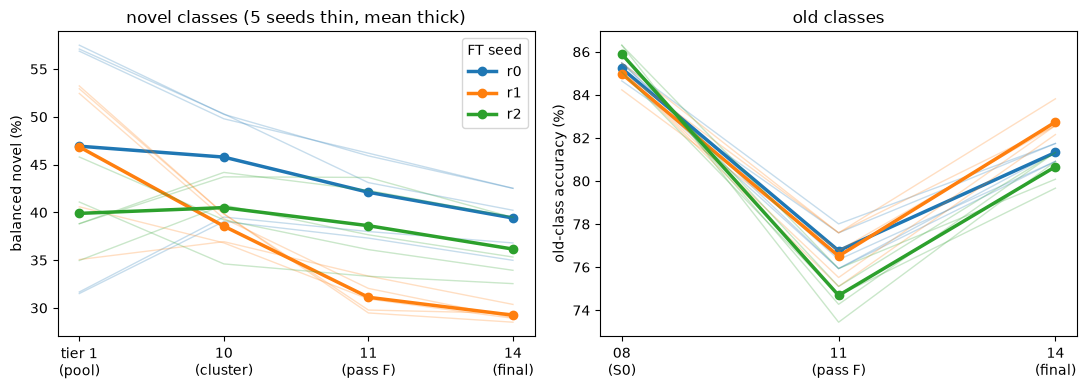

In [8]:
# 4.1 per FT seed: tier 1 (pool, one-to-one Hungarian, E09.05 on the v2 snapshots) -> 10 -> 11 -> 14 for the novel classes,
#     08 -> 11 -> 14 for the old ones; losses per stage and the r1 - r0 gap; figure
import matplotlib.pyplot as plt
tier1 = {run.replace("gc10_v2_ft_", ""): json.loads(next((ROOT / "runs").glob(f"*__gc10_e09_05_v2_{run.split('_ft_')[1]}/metrics.json"))
                                                    .read_text())["k5_bal_acc_hungarian"] for run in RUNS}
T41 = T31[["ft", "bal09", "bal10", "bal11", "bal14", "old08", "old11", "old14"]].copy()
T41.insert(1, "tier1", pd.Series(tier1))
for c in ("old08", "old11", "old14"):
    T41[c] = T41[c] / 241
M41 = T41.groupby("ft").mean()
print("mean by FT seed (fractions):")
print(M41.round(3).to_string())
nov, old = ["tier1", "bal10", "bal11", "bal14"], ["old08", "old11", "old14"]
D41 = pd.DataFrame({f"{a}->{b}": 100 * (M41[b] - M41[a]) for seq in (nov, old) for a, b in zip(seq, seq[1:])})
print("\nchange per stage (points):")
print(D41.round(1).to_string())
print("\nr1 - r0 per step (points):", {c: round(100 * (M41.loc["r1", c] - M41.loc["r0", c]), 1) for c in nov + old})

fig41, ax41 = plt.subplots(1, 2, figsize=(11, 4))
for r, col in zip(("r0", "r1", "r2"), ("C0", "C1", "C2")):
    sub = T41[T41.ft == r]
    for ax, seq, lab in ((ax41[0], nov, ["tier 1\n(pool)", "10\n(cluster)", "11\n(pass F)", "14\n(final)"]),
                         (ax41[1], old, ["08\n(S0)", "11\n(pass F)", "14\n(final)"])):
        x = np.arange(len(seq))
        for _, row in sub.iterrows():
            ax.plot(x, 100 * row[seq].to_numpy(float), color=col, alpha=0.25, lw=1)
        ax.plot(x, 100 * M41.loc[r, seq].to_numpy(float), color=col, lw=2.5, marker="o", label=r)
        ax.set_xticks(x, lab)
ax41[0].set_ylabel("balanced novel (%)"); ax41[0].set_title("novel classes (5 seeds thin, mean thick)")
ax41[1].set_ylabel("old-class accuracy (%)"); ax41[1].set_title("old classes")
ax41[0].legend(title="FT seed")
fig41.tight_layout(); plt.show()

- **Kết quả** (trung bình 5 seed; r0 / r1 / r2):
  - Lớp mới:

    | bước | r0 | r1 | r2 |
    |---|---|---|---|
    | tầng 1 (pool) | 0.469 | 0.469 | 0.399 |
    | 10 (cụm, tên của pipeline) | 0.458 | 0.386 | 0.405 |
    | 11 (lượt F) | 0.421 | 0.311 | 0.386 |
    | 14 (cuối) | 0.394 | 0.292 | 0.362 |

    Mỗi khâu: tầng 1→10 −1.1 / −8.3 / +0.6; 10→11 −3.7 / −7.4 / −1.9; 11→14 −2.7 / −1.9 / −2.4 điểm.
  - Lớp cũ: 08 → 11 → 14 = 85.2 → 76.8 → 81.3 / 85.0 → 76.5 → 82.7 / 85.9 → 74.7 → 80.7%. Lượt F mất 8.5–11.2 điểm; 12–13 lấy lại 4.6–6.2.
  - Khoảng cách r1 − r0: tầng 1 −0.1; 10 −7.2; 11 −11.0; 14 −10.2 điểm. Ở lớp cũ: 08 −0.2, 11 −0.2, 14 +1.4.
  - Trong r0, tầng 1 chia hai nhóm: s0–s2 khoảng 0.57 (có cụm crease), s3–s4 khoảng 0.32. Ở cột 10, hai nhóm còn 0.50 và 0.39.
- **Ý nghĩa**:
  - Đúng như dự đoán (các số tính từ §3.1). Riêng khâu 11→14 của r1 là −1.9, hơi dưới khoảng 2–3.
  - Q14.04 trên 15 chuỗi mặc định:
    - r1 bằng r0 ở tầng 1 nhưng thua 10.2 điểm ở cuối;
    - 7.2 điểm mất ở khâu từ pool sang test và đặt tên (tầng 1 → 10), thêm 3.8 điểm ở lượt F (10 → 11);
    - khâu 11 → 14 làm mọi FT seed mất như nhau (2–3 điểm), nên không góp vào khoảng cách.
  - Tầng 1 không xếp hạng được FT seed theo tầng 2: r1 bằng r0 ở tầng 1, nhưng tầng 2 là r0 > r2 > r1. Dùng tầng 1 để sàng lọc (QD18) phải kèm ít nhất cột 10, tức cụm có tên của pipeline, trên tập test.
  - Lớp cũ gần như không phân biệt ba FT seed ở 08 và 11. Ở 14, r1 cao nhất (+1.4 so với r0) đúng lúc lớp mới thấp nhất: cùng một đánh đổi ổn định–thích nghi, nhìn ở mức FT seed.
    - [SUY LUẬN] Khe mới của r1 vừa thắng ít ảnh mới vừa cướp ít ảnh cũ (5.4 ảnh so với 9.4 và 12.6). Điều này hợp với việc khe mới của r1 yếu hơn nói chung, chứ không chỉ đặt sai tên.
  - Lớp cũ mất nhiều nhất ở lượt F (8.5–11.2 điểm), nhưng lượt F chỉ dùng để lọc. Thứ đến bảng S1 là phần còn lại sau 12–13: 3.9 / 2.2 / 5.2 điểm (M_f).

### 4.2 Đặt tên khi chấm, trên dự đoán của bộ phân lớp cuối

Ba cách đặt tên, áp lên `slot_14` của 214 ảnh test lớp mới. Ảnh vào khe cũ thì sai dưới mọi cách.
- (a) tên của pipeline (QD15): Hungarian cân theo số ảnh trên dự đoán của k-means. Kiểm: phải ra đúng balanced ở cột 14.
- (b) QD14: Hungarian cân theo số ảnh trên chính dự đoán của bộ phân lớp, như giao thức GCD chấm trên dự đoán của mô hình (Vaze et al., CVPR 2022).
- (c) Hungarian cân theo recall (1/n_c) trên dự đoán của bộ phân lớp.

(b) và (c) chọn tên và chấm trên cùng một tập, nên tính thêm bản kiểm chéo hai nửa, giống hệt `10` §3.2: 500 lần chia theo lớp, `RandomState(10)`.

Đã thấy trước (`10` §3.2, mức cụm): sau kiểm chéo, (c) − (a) = r0 +2.2, r1 +6.7, r2 −2.4 điểm; (a) gần như không bị thổi phồng.

Dự đoán [SUY LUẬN]:
- (a) tái lập cột 14 ở 15/15;
- S1_New của (b) ≥ (a) ở 15/15, theo cách dựng. (b) đặt tên khác (a) ở r1 s0–s2 và tối đa 2 ảnh chụp khác;
- sau kiểm chéo, (c) − (a) = r1 +4 đến +8 điểm, r0 0 đến +3, r2 ≤ 0. Kết luận của `10` §3.2 vẫn giữ ở bộ phân lớp cuối.
- kiểm theo cách dựng: balanced của (c) chấm trên cùng tập ≥ cả (a) lẫn (b) ở 15/15.

In [9]:
# 4.2 naming at evaluation on the final classifier's predictions (slot_14) of the 214 novel test images:
#     (a) pipeline names (QD15, k-means test predictions), (b) count Hungarian on the classifier's predictions (QD14),
#     (c) recall Hungarian on them, recall = hits / all images of the class (old-slot ones included);
#     (b), (c) also cross-fitted on split halves exactly as 10 §3.2 (500 splits, RandomState(10))
from scipy.optimize import linear_sum_assignment
def naming_count(n):
    r_, c_ = linear_sum_assignment(-n); out = [None] * 5
    for c, k in zip(r_, c_): out[k] = int(c)
    return out
def naming_recall(n, tot):
    return naming_count(n / np.maximum(tot, 1)[:, None])
def score(n, tot, naming):
    """balanced novel and number right: cluster k counts for class naming[k]; tot = images per class (old-slot ones included)."""
    hit = np.array([n[naming[k], k] for k in range(5)]); cls = np.array(naming)
    rec = np.zeros(5); rec[cls] = hit / tot[cls]
    return rec.mean(), int(hit.sum())
def counts(y, c, sel):
    n = np.zeros((5, 5), int); m = sel & (c >= 0)
    np.add.at(n, (y[m], c[m]), 1)
    return n, np.bincount(y[sel], minlength=5)

rs42, rows42 = np.random.RandomState(10), []
for run in RUNS:
    t = L[run]["test1"]
    y = t["y"].to_numpy() - 5
    c = np.where(t["slot_14"].to_numpy() >= 5, t["slot_14"].to_numpy() - 5, -1)   # cluster of the slot, -1 = old slot
    pi = replay.snapshots(run)["10"]["out"]["pi_test"]
    na = [int(pi[k]) for k in range(5)]
    n, tot = counts(y, c, np.ones(len(y), bool))
    nb, nc = naming_count(n), naming_recall(n, tot)
    (ba, ra), (bb, rb), (bc, rc) = score(n, tot, na), score(n, tot, nb), score(n, tot, nc)
    cv = {"b": [], "c": []}
    for _ in range(500):
        half = np.zeros(len(y), bool)
        for k in range(5):
            idx = rs42.permutation(np.flatnonzero(y == k)); half[idx[: len(idx) // 2]] = True
        for fit, ev in ((half, ~half), (~half, half)):
            nf, tf = counts(y, c, fit); ne, te_ = counts(y, c, ev)
            cv["b"].append(score(ne, te_, naming_count(nf))[0]); cv["c"].append(score(ne, te_, naming_recall(nf, tf))[0])
    rows42.append(dict(snap=run.replace("gc10_v2_ft_", ""), a=ba, a_eq_col14=abs(ba - T31.loc[run.replace("gc10_v2_ft_", ""), "bal14"]) < 1e-12,
                       b_same=bb, c_same=bc, c_ge_ab=bc >= max(ba, bb) - 1e-12, b_cv=np.mean(cv["b"]), c_cv=np.mean(cv["c"]),
                       new_a=ra, new_b=rb, new_c=rc, names_b_differ=nb != na, names_c_differ=nc != na))
T42 = pd.DataFrame(rows42).set_index("snap")
T42["b_cv_minus_a"], T42["c_cv_minus_a"] = 100 * (T42.b_cv - T42.a), 100 * (T42.c_cv - T42.a)
print(T42.round(3).to_string())
T42["ft"] = [i[:2] for i in T42.index]
print("\nmean by FT seed:")
print(T42.groupby("ft")[["a", "b_same", "c_same", "b_cv", "c_cv", "b_cv_minus_a", "c_cv_minus_a", "new_a", "new_b", "new_c"]].mean().round(3).to_string())
print("checks: (a) = column 14 in", f"{int(T42.a_eq_col14.sum())}/15", "| new_b >= new_a in", f"{int((T42.new_b >= T42.new_a).sum())}/15",
      "| c_same >= a, b in", f"{int(T42.c_ge_ab.sum())}/15",
      "| names (b) differ from (a) in", f"{int(T42.names_b_differ.sum())}/15", "| (c) differ in", f"{int(T42.names_c_differ.sum())}/15")

           a  a_eq_col14  b_same  c_same  c_ge_ab   b_cv   c_cv  new_a  new_b  new_c  names_b_differ  names_c_differ  b_cv_minus_a  c_cv_minus_a
snap                                                                                                                                            
r0_s0  0.425        True   0.425   0.468     True  0.420  0.437    123    123    122           False            True        -0.479         1.220
r0_s1  0.425        True   0.425   0.468     True  0.423  0.440    123    123    122           False            True        -0.184         1.492
r0_s2  0.402        True   0.402   0.445     True  0.400  0.407    105    105    104           False            True        -0.178         0.483
r0_s3  0.350        True   0.368   0.368     True  0.358  0.335    121    122    122            True            True         0.770        -1.495
r0_s4  0.368        True   0.368   0.368     True  0.352  0.335    122    122    122           False           False        -1.649

- **Kết quả** (lần chạy thứ hai; lần đầu, cách (c) chuẩn hoá recall theo số ảnh vào khe mới thay vì theo cả lớp, nên chưa tối ưu được balanced; đã sửa và thêm phép kiểm theo cách dựng):
  - Các phép kiểm:
    - (a) tái lập cột 14 ở 15/15;
    - S1_New của (b) ≥ (a) ở 15/15;
    - balanced của (c), chấm trên cùng tập, ≥ (a) và ≥ (b) ở 15/15.
  - Trung bình theo FT seed (r0 / r1 / r2):
    - (a) QD15: 0.394 / 0.292 / 0.362;
    - (b) QD14, chấm trên cùng tập: 0.398 / 0.401 / 0.369; kiểm chéo: 0.391 / 0.354 / 0.359;
    - (c) cân theo recall, chấm trên cùng tập: 0.423 / 0.401 / 0.369; kiểm chéo: 0.391 / 0.375 / 0.341.
  - Hiệu sau kiểm chéo so với (a):
    - (b): −0.3 / +6.2 / −0.3 điểm;
    - (c): −0.3 / +8.2 / −2.0 điểm.
    - Ở r1 s0–s2, hai cách hơn (a) 7.8–13.2 điểm; ở r1 s3, s4 chỉ 0.4–3.5.
  - (b) đặt tên khác (a) ở 8/15 ảnh chụp (cả 5 ảnh chụp của r1; r0 s3; r2 s1, s2); (c) khác ở 11/15. S1_New của (b) hơn (a) 9–12 ảnh ở r1, 0–1 ảnh ở các ảnh chụp khác.
- **Ý nghĩa**:
  - Đúng ở các phép kiểm, ở dấu của r2 và độ lớn của r1. Sai ở số ảnh chụp mà (b) đặt tên khác (8 chứ không tối đa 5), và ở r0, nơi (c) không hơn (a).
  - Xác nhận [SUY LUẬN] của `10` §3.2 trên bộ phân lớp cuối:
    - cách đặt tên của pipeline làm r1 mất 6–8 điểm balanced, tập trung ở r1 s0–s2, nơi cụm do crease sở hữu bị gán tên inclusion;
    - ở r0 và r2, đổi cách đặt tên gần như không đổi gì, hoặc có hại (r2, cách (c)).
  - Với Q14.04: trong 10.2 điểm r1 thua r0 ở cuối pipeline, khoảng 6 điểm là cách chấm, không phải cái mô hình học được. Sau khi đặt tên lại theo dự đoán của bộ phân lớp và kiểm chéo, khoảng cách còn khoảng 3.7 điểm (theo (b)).
  - Không đổi QD25: E09.07 đã khoá QD15; cách (c) vẫn nhiễu ở các lớp 6 và 11 ảnh, như `10` §3.2 đã nói.
    - [SUY LUẬN] QD14, tức Hungarian cân theo số ảnh trên dự đoán của chính mô hình, ổn định gần bằng QD15 (độ thổi phồng 0.3–4.7 điểm) và sát giao thức GCD chuẩn hơn. Là ứng viên khi tiền đăng ký E09.06; khi đó phải ghi đã thấy §4.2.

## Summary (EN)

1. **Step 14 reproduces exactly, and four of the six S1 metrics are identities.** `rerun` gives `acc1` with max|diff| 0 (driver 617.42 → 621.14). On GC10 t1 the old test set of session 1 is the S0 test set, so the S0 row equals the Old row; M_d = S1_New, M_f = S0_S0test − S1_Old, final_All = S1_All. All five identities hold on 15/15 snapshots (§1.1, §2.1).
2. **The old classes can only lose in session 1, and they lose only by capture.** The 5 old slots of `params_f` and `params1` are bit-identical to `params0` on 15/15 snapshots (zero gradient, zero Adam update). No old test image goes from wrong at 08 to right at 11 or 14 (0 over 15), and the images lost from 08 to 14 equal the M_f proxy counted in images (4–15 per snapshot, 137 in all). M_f on this code is interference by the new slots, not parameter drift, and old→old errors are S0 errors that no step 09–14 can fix (§2.1, §3.1).
3. **Paper vs code.** D15: M_f on D_l as the paper defines it (764 S0 training images) is 0.9–3.4 points, below the test proxy (1.7–6.2) on 14/15 snapshots. D25: at the final classifier the log det term favours the OLD slots (mean Δb −0.11 to −0.18 on 15/15), the opposite sign of step 12 (+0.35), because the S stop leaves the new slots √2 wider in mean det (ratio 1.414–1.417). Dropping it moves 1–9 test images per snapshot towards new slots: −14 old images and +0.57 balanced points over 15 (§2.2).
4. **Ledger at step 14 and the thresholds of E09.07.** Balanced novel at 14 is 0.394 / 0.292 / 0.362 (FT seeds r0 / r1 / r2). T = 0.0273 and B = 0.615 points of S1_Old (1.48 images), the pooled within-FT-seed SDs fixed in the pre-registration part 2 (§3.3; per-FT-seed SD of balanced novel 0.034 / 0.007 / 0.032; the part-1 formula, a mean of SDs, gives 0.0244 and 0.599). From 11 to 14 (filter plus early stop), each snapshot gets back 9–18 old test images (none lost) and loses a net 1–9 novel ones, about 2.5 old images per novel image (§3.1).
5. **The cross-group errors are model errors, not label ambiguity (Q08.02).** Over 15 snapshots: old→old 463, old→new 203, new→old 411, new→new 1205. Inclusion makes 70% of new→old, mostly into oil_spot (197) and water_spot (59). Only 33/411 have a box of the destination class, and 0/59 inclusion→water images have a water_spot box, which rejects the co-occurrence explanation. Water_spot makes 74% of the captures, mostly by silk-owned slots, with 0/203 boxes of the capturing class. Three quarters of the novel errors stay among the novel slots, and all 6 rolled_pit test images are wrong in 15/15 snapshots (§3.2).
6. **Where the points go (Q14.04).** Novel, per FT seed: tier 1 → cluster level → pass F → final = 0.469 → 0.458 → 0.421 → 0.394 (r0), 0.469 → 0.386 → 0.311 → 0.292 (r1), 0.399 → 0.405 → 0.386 → 0.362 (r2). r1 equals r0 at tier 1 and ends 10.2 points below: 7.2 points at pool→test plus naming, 3.8 at pass F; steps 12–14 cost every seed 2–3 points. Old: 85 → 75–77 (pass F) → 81–83 (final) (§4.1).
7. **Naming at evaluation.** On the final classifier's predictions, naming by its own predictions (QD14, cross-fitted) beats the pipeline naming (QD15) by 6.2 points at r1 and is level at r0, r2 (−0.3). About 6 of the 10.2 points by which r1 trails r0 come from how the clusters are named at scoring. QD25 stays as fixed (QD15) for E09.07; QD14 is a candidate for E09.06 (§4.2).